# Practice Session 09: Forecasting

In this session we will do some time series forecasting on a weather-related time series, which contains temperature, precipitation, and wind speed data for the Barcelona airport. 

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

⭐ **Regarding the usage of generative AI.** You may use generative AI to (a) understand how to do certain operations, and (b) generate short snippets of code, that you can incorporate into your practice after reviewing them. In that case, add a comment `#AI` before the snippet. You can also add `#AI (edited)` if you edited the code before incorporating it.

⚠️ It is forbidden to use generative AI in these practices for answering the text-based questions.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

Author: <font color="#2680EB">Your name here</font>

E-mail: <font color="#2680EB">Your e-mail here</font>

AI used: <font color="#2680EB">Maker and model, or "none".</font>

Date: <font color="#2680EB">The current date here</font>

In [1]:
import io
import json
import pandas as pd
import datetime
import numpy as np
import scipy.stats as stats
import math

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


# 0. Dataset

The dataset we will use is was obtained from [AEMET's Open Data](https://opendata.aemet.es/centrodedescargas/inicio) initiative. Anyone can request an API Key and then use their services to obtain climatological variables ("*valores climatológicos*").

We will read it into a dataframe using Pandas' [read_csv](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html) function.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [2]:
# LEAVE AS-IS

INPUT_FILE = "aemet-barcelona-airport-2016-2026.json"
weather = pd.read_json(INPUT_FILE)

display(weather.head(5))
display(weather.tail(5))

,fecha,indicativo,nombre,provincia,altitud,tmed,prec,tmin,horatmin,tmax,...,horaPresMax,presMin,horaPresMin,hrMedia,hrMax,horaHrMax,hrMin,horaHrMin,pintMax,horaPIntMax
0,2016-07-01,0201D,BARCELONA,BARCELONA,6,"24,1","0,0","21,9",03:40,"26,3",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-07-02,0201D,BARCELONA,BARCELONA,6,"24,6","0,0","22,3",04:40,"27,0",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-07-03,0201D,BARCELONA,BARCELONA,6,"23,4","0,0","21,9",11:00,"24,9",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-07-04,0201D,BARCELONA,BARCELONA,6,"23,8","0,0","21,8",04:40,"25,9",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-07-05,0201D,BARCELONA,BARCELONA,6,"25,3","0,0","23,2",00:10,"27,4",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,fecha,indicativo,nombre,provincia,altitud,tmed,prec,tmin,horatmin,tmax,...,horaPresMax,presMin,horaPresMin,hrMedia,hrMax,horaHrMax,hrMin,horaHrMin,pintMax,horaPIntMax
3725,2026-09-14,0076,BARCELONA AEROPUERTO,BARCELONA,1,"24,4","0,0","19,7",05:29,"29,1",...,Varias,"1018,7",16,67.0,83.0,Varias,46.0,10:44,"0,0",NaN
3726,2026-09-15,0076,BARCELONA AEROPUERTO,BARCELONA,1,"26,3","0,0","21,3",05:30,"31,3",...,Varias,"1016,5",16,56.0,68.0,Varias,37.0,09:32,"0,0",NaN
3727,2026-09-16,0076,BARCELONA AEROPUERTO,BARCELONA,1,"23,5","48,0","18,0",21:25,"29,0",...,Varias,"1015,4",16,66.0,94.0,23:05,53.0,07:44,"112,2",21:20
3728,2026-09-17,0076,BARCELONA AEROPUERTO,BARCELONA,1,"22,2","1,1","18,5",00:35,"25,8",...,Varias,"1014,8",18,69.0,94.0,00:32,56.0,11:08,"-0,3",Varias
3729,2026-09-18,0076,BARCELONA AEROPUERTO,BARCELONA,1,"22,2",Ip,"19,0",05:31,"25,5",...,Varias,"1015,0",03,71.0,89.0,04:39,56.0,11:23,"6,0",02:20


The columns on this dataset are as follows:

| id          | description                                                         | data_type | units                      |
| ----------- | ------------------------------------------------------------------- | ---------- | --------------------------- |
| fecha       | date (AAAA-MM-DD)                                          | string           |                             |
| indicativo  | *indicativo climatológico*                                            | string           |                             |
| nombre      | name (location) of the station                                   | string           |                             |
| provincia   | province of the station                                            | string           |                             |
| altitud     | altitude of the station above sea level                  | float            | m                           |
| tmed        | average daily temperature                                            | float           | grados celsius              |
| prec        | daily rainfall from 07 to 07                                     | float           | mm (Ip = less than 0.1 mm) |
| tmin        | minimum temperature of the day                                          | float           | ºC                          |
| horatmin    | hour and minute of minimum temperature                              | string          | UTC                         |
| tmax        | maximum temperature of the day                                          | float           | ºC                          |
| horatmax    | hour and minute of maximum temperature                              | string          | UTC                         |
| dir         | direction of the fastest wind gust                                        | float           | decenas de grado            |
| velmedia    | average wind speed                                          | float           | m/s                         |
| racha       | fastest wind gust                                             | float           | m/s                         |
| horaracha   | hour and minute of fastest wind gust                                    | string          | UTC                         |
| sol         | hours of sun                                                            | float           | hours                       |
| presmax     | maximum pressure at the level of reference of the station               | float           | hPa                         |
| horapresmax | hour of maximum pressure (rounded to nearest hour) | string          | UTC                         |
| presmin     | minimum pressure at the level of reference of the station               | float           | hPa                         |
| horapresmin | hour of minimum pressure (rounded to nearest hour) | string          | UTC

Next, we will rename columns so that more people can understand their names, using the following equivalence:

<font size="-1" color="gray">(Remove this cell when delivering.)</font>


In [3]:
# LEAVE AS-IS

COLUMN_NAMES = {
  "fecha" : "date",
  "indicativo" : "station_num",
  "nombre" : "station_name",
  "provincia" : "station_province",
  "altitud" : "station_altitude",
  "tmed" : "temp_avg",
  "tmin" : "temp_min",
  "tmax" : "temp_max",
  "horatmin" : "temp_min_time",
  "horatmax" : "temp_max_time",
  "prec" : "rainfall",
  "dir" : "windspeed_dir",
  "velmedia" : "windspeed_avg",
  "racha" : "windspeed_gusts",
  "horaracha" : "windspeed_gusts_time",
  "sol" : "sun",
  "presMax" : "pressure_max",
  "horaPresMax" : "pressure_max_time",
  "presMin" : "pressure_min",
  "horaPresMin" : "pressure_min_time",
  "hrMedia": "relhumidity_mean",
  "hrMax": "relhumidity_max",
  "hrMin": "relhumidity_min",
  "horaHrMax": "relhumidity_max_time", 
  "horaHrMin": "relhumidity_min_time"
}

weather_renamed = weather.copy()
weather_renamed.rename(columns=COLUMN_NAMES, inplace=True)
list(weather_renamed.columns)

['date',
 'station_num',
 'station_name',
 'station_province',
 'station_altitude',
 'temp_avg',
 'rainfall',
 'temp_min',
 'temp_min_time',
 'temp_max',
 'temp_max_time',
 'windspeed_dir',
 'windspeed_avg',
 'windspeed_gusts',
 'windspeed_gusts_time',
 'sun',
 'pressure_max',
 'pressure_max_time',
 'pressure_min',
 'pressure_min_time',
 'relhumidity_mean',
 'relhumidity_max',
 'relhumidity_max_time',
 'relhumidity_min',
 'relhumidity_min_time',
 'pintMax',
 'horaPIntMax']

# 1. Preparation

We will perform fairly typical time series data preparation steps.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

## 1.1. Cleaning <font color="#2680EB">[20%]</font>

We will not use the ``*_time`` columns, which record at what time of the day, so we will drop those columns.

Additionally, we will remove other columns. This can be done using ``df.drop(columns=[...], inplace=True)``

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Answer the following question.**</font>

**Answer:**

We will remove the columns station_num, station_name, station_province, station_altitude. Why?

* YOUR ANSWER HERE

<font size="+1" color="#2680EB">**Remove the station number, name, province, and altitude columns, plus all the _time columns.**</font>

In [ ]:
weather_column_sel = weather_renamed.copy()

# YOUR ANSWER HERE

The next cell prints the beginning and the end of the time series.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [5]:
# LEAVE THIS CODE AS-IS

display(weather_column_sel.head(5))
display(weather_column_sel.tail(5))

,date,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
0,2016-07-01,"24,1","0,0","21,9","26,3",99.0,"3,1","5,8",NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-07-02,"24,6","0,0","22,3","27,0",13.0,"3,6","7,5",NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-07-03,"23,4","0,0","21,9","24,9",20.0,"4,2","8,9",NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-07-04,"23,8","0,0","21,8","25,9",25.0,"3,3","6,7",NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-07-05,"25,3","0,0","23,2","27,4",35.0,"3,1","6,4",NaN,NaN,NaN,NaN,NaN,NaN,NaN


,date,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
3725,2026-09-14,"24,4","0,0","19,7","29,1",23.0,"6,7","12,5","1022,0","1018,7",67.0,83.0,46.0,"0,0",NaN
3726,2026-09-15,"26,3","0,0","21,3","31,3",22.0,"4,7","10,3","1019,5","1016,5",56.0,68.0,37.0,"0,0",NaN
3727,2026-09-16,"23,5","48,0","18,0","29,0",3.0,"4,7","15,0","1019,7","1015,4",66.0,94.0,53.0,"112,2",21:20
3728,2026-09-17,"22,2","1,1","18,5","25,8",24.0,"4,2","10,8","1017,9","1014,8",69.0,94.0,56.0,"-0,3",Varias
3729,2026-09-18,"22,2",Ip,"19,0","25,5",19.0,"3,6","8,9","1019,6","1015,0",71.0,89.0,56.0,"6,0",02:20


Now, we need to process the numerical data. Notice that weather data may contain **gaps**:

* The station may malfunction (e.g., power outage with an empty battery or no backup energy surce).
* An instrument may malfunction, so a variable might not be recorded properly on a given day.

Plus, in this specific dataset there are **domain-specific** and **source-specific** considerations:

* Atmospheric pressure and relative humidity have only been recorded since around 2019 and 2022, respectively.
* Decimal numbers are recorded with commas, which is the standard in Catalan and Spanish, but not in Python.
* Negligible or trace precipitation amounts are described a ``Ip`` ("*inapreciable*")

Hence, we will do the following:

1. Convert numbers with commas, possibly represented as strings, into floating point numbers.
2. Convert the ``Ip`` string to a 0.0.
3. Convert everything else that is not a number to ``np.nan``

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Implement function aemet_cleanup,** which should perform the actions 1, 2, 3 above.</font>

In [ ]:
def aemet_cleanup(x):
    val = str(x)

    # YOUR ANSWER HERE

Test it with the following cases:

* When giving an empty string, the string "Varias", or the string "06:30", the function should return not a number.
* With the strings "0,0" and "Ip", it should return a zero.
* With a decimal string using a comma (e.g., "13,5") it should return the corresponding number (13.5)
* With an integer as a string (e.g., "13") it should return the corresponding number (13.0)

Use the assert function to do these tests, e.g.:

```python
assert 1 + 1 == 2
```

Use the function [numpy.isnan](https://numpy.org/doc/stable/reference/generated/numpy.isnan.html) to test whether something is a NaN (not a number) or not.

```python
assert np.isnan(...)
```

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Implement tests for your function aemet_cleanup.**</font>

In [ ]:
assert np.isnan(aemet_cleanup(""))
assert 0.0 == aemet_cleanup("0,0")
assert 0.0 == aemet_cleanup("Ip")

# Add more cases below

# YOUR ANSWER HERE

Apply this function to various columns containing numerical data, as specified below.

To apply function *f* to column *c* of dataframe *df*, we use `df[c] = df[c].apply(f)`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Apply the cleanup function to these columns:** 'temp_min', 'temp_max', 'temp_avg', 'rainfall', 'windspeed_dir', 'windspeed_avg', 'windspeed_gusts', 'pressure_min', 'pressure_max', 'relhumidity_min', 'relhumidity_max' </font>

In [ ]:
weather_clean = weather_column_sel.copy()

# YOUR ANSWER HERE

To verify, we print the first five and last five elements of the time series.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [9]:
# LEAVE THIS CODE AS-IS

display(weather_clean.head(5))
display(weather_clean.tail(5))

,date,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
0,2016-07-01,24.1,0.0,21.9,26.3,99.0,3.1,5.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-07-02,24.6,0.0,22.3,27.0,13.0,3.6,7.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-07-03,23.4,0.0,21.9,24.9,20.0,4.2,8.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-07-04,23.8,0.0,21.8,25.9,25.0,3.3,6.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-07-05,25.3,0.0,23.2,27.4,35.0,3.1,6.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,date,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
3725,2026-09-14,24.4,0.0,19.7,29.1,23.0,6.7,12.5,1022.0,1018.7,67.0,83.0,46.0,"0,0",NaN
3726,2026-09-15,26.3,0.0,21.3,31.3,22.0,4.7,10.3,1019.5,1016.5,56.0,68.0,37.0,"0,0",NaN
3727,2026-09-16,23.5,48.0,18.0,29.0,3.0,4.7,15.0,1019.7,1015.4,66.0,94.0,53.0,"112,2",21:20
3728,2026-09-17,22.2,1.1,18.5,25.8,24.0,4.2,10.8,1017.9,1014.8,69.0,94.0,56.0,"-0,3",Varias
3729,2026-09-18,22.2,0.0,19.0,25.5,19.0,3.6,8.9,1019.6,1015.0,71.0,89.0,56.0,"6,0",02:20


 ## 1.2. Index by date and plotting <font color="#2680EB">[10%]</font>

The next code indexes the data by date.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [10]:
# LEAVE AS-IS

weather_indexed = weather_clean.copy()

weather_indexed.set_index('date', inplace=True)
weather_indexed.index = pd.to_datetime(weather_indexed.index)
display(weather_indexed.head(3))

,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
date,,,,,,,,,,,,,,
2016-07-01,24.1,0.0,21.9,26.3,99.0,3.1,5.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-07-02,24.6,0.0,22.3,27.0,13.0,3.6,7.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-07-03,23.4,0.0,21.9,24.9,20.0,4.2,8.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The following functions, which you can leave as-is, are useful for plotting.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [11]:
# LEAVE THIS CELL AS-IS

# Configure font sizes
plt.rc('font', size=10) 
plt.rc('axes', labelsize=16)
plt.rc('legend', fontsize=16)

# Flexible plotting function
def plot_min_max(df, min_col='', max_col='', avg_col='', avg_label='Average', 
                     title='Weather', xlabel='Date', ylabel='Variable'):

    # The instructor used Gemini to create this plot using seaborn
    
    # Apply Seaborn aesthetic theme
    sns.set_theme(style='whitegrid')

    # Create figure and axis
    plt.figure(figsize=(16, 5))

    # Fill region between min and max
    if min_col and max_col:
        plt.fill_between(df.index, df[min_col], df[max_col], color='lightgray', alpha=0.5)

    # Plot average line using Seaborn
    if avg_col:
        sns.lineplot(data=df, x=df.index, y=avg_col, color='black', label=avg_label)

    # Label axis and title
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    plt.show()
    
# Plot function
def plot_variable(df, col='', label='', title='Weather', xlabel='Date', ylabel=''):
    
    plot_min_max(df, title=title, xlabel=xlabel, ylabel=ylabel, avg_col=col, avg_label=label)

    plt.show()


We can now plot some values. Note that there are gaps in the temperature series, particularly on the first half of 2018.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

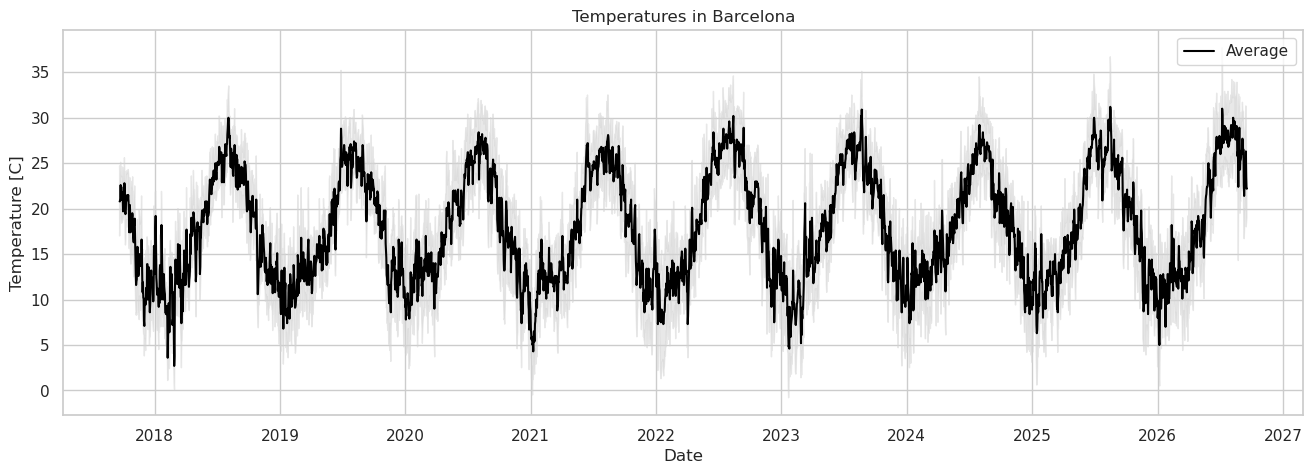

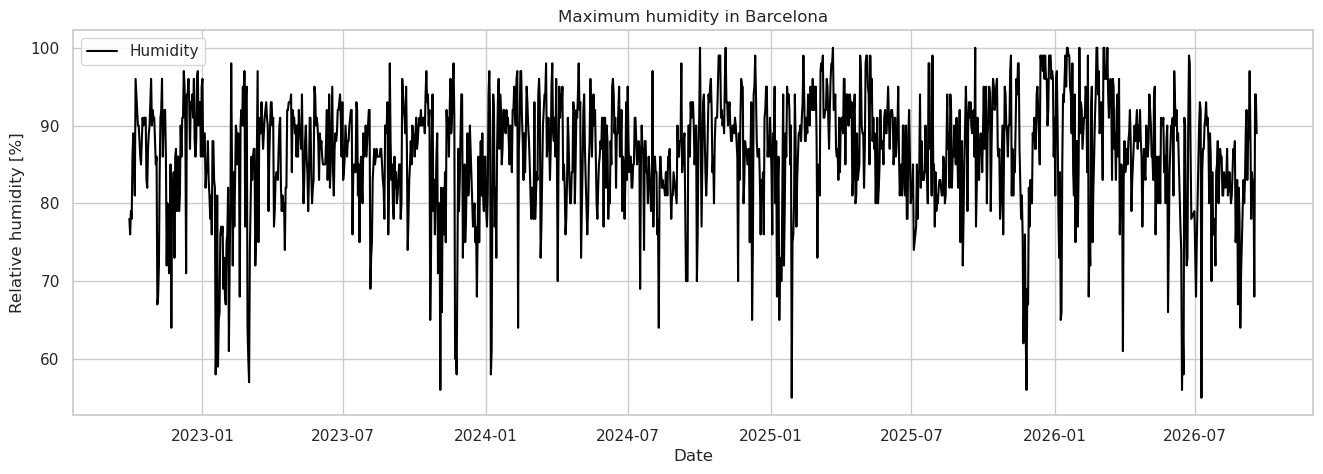

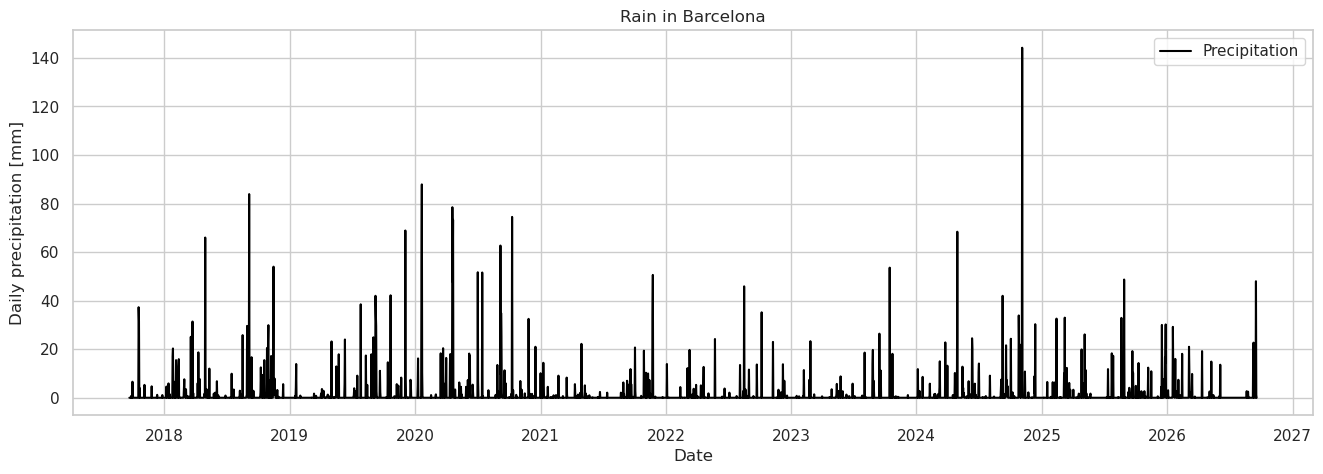

In [12]:
# LEAVE AS-IS

# Retrieve the last 9 years
weather_sample = weather_indexed.tail(9*365)

# Plot temperature
plot_min_max(weather_sample, title='Temperatures in Barcelona', ylabel='Temperature [C]',
             min_col='temp_min', max_col='temp_max', avg_col='temp_avg')

# Plot humidity
plot_variable(weather_sample, title='Maximum humidity in Barcelona', ylabel='Relative humidity [%]',
             col='relhumidity_max', label='Humidity')

# Plot precipitation
plot_variable(weather_sample, title='Rain in Barcelona', ylabel='Daily precipitation [mm]', 
            col='rainfall', label='Precipitation')


<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Answer:**

Do you observe seasonality in these plots? If yes, in which one(s)? Which type of seasonality (weekly, monthly, yearly)?

* YOUR ANSWER HERE

In which plot(s) you do not observe seasonality? Why do you think that happens, if weather is supposed to be cyclical?

* YOUR ANSWER HERE


## 1.3. Smoothing <font color="#2680EB">[20%]</font>

We will compute a moving average of the previous `window_size` days (e.g., 7) as a way of smoothing the time series. Create a function `moving_average(df, window_size)` that computes a **moving average on all columns** of the given dataframe, and returs a new dataframe with the averages. This function can assume that all columns in the input dataframe are numeric.

A possible implementation is to iterate through numbers from `0` to `len(df)` and create a sub-dataframe of up to `window_size` rows with the corresponding rows. 

The following might be helpful:

* `window = df.iloc[a:b]` to return rows from *a* to *b* on a dataframe.
* `window.mean(numeric_only=True)` to obtain a series containing the averages of all columns in a dataframe.

If you feel more comfortable working with matrices, you can also use matrices instead of dataframes, and you can also instead of creating a sub-dataframe compute in-place.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Implement the moving_average function.**</font>

In [ ]:
def moving_average(df, window_size):

    averages = []
    length = len(df)
    
    for i in range(length):

        # YOUR ANSWER HERE

    smoothed = pd.DataFrame(averages, columns=df.columns)
    smoothed.set_index(df.index, inplace=True)
    
    return smoothed

Apply this code over the ``weather_sample`` and check correctness by verifying the following:

* For day 1, it should be equivalent to the original series
* For day 2, it should be the average of the first two days of the original series
* For day 7, it should be the average of the first 7 days of the original series
* For day 8, it should be the average of the second to the eight day of the original series
* For the last day, it should be the average of the last 7 days in the series

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [14]:
# LEAVE AS-IS

window_size = 7
weather_smoothed = moving_average(weather_sample, window_size)

display(weather_sample.head(10))
display(weather_smoothed.head(10))

Processing 0/3285 (0.0%)
Processing 500/3285 (15.2%)
Processing 1000/3285 (30.4%)
Processing 1500/3285 (45.7%)
Processing 2000/3285 (60.9%)
Processing 2500/3285 (76.1%)
Processing 3000/3285 (91.3%)


,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
date,,,,,,,,,,,,,,
2017-09-21,20.8,0.0,17.0,24.7,22.0,3.6,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-22,20.8,0.0,19.0,22.7,99.0,1.7,7.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-23,21.2,0.0,18.5,24.0,20.0,3.3,8.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-24,22.6,0.0,20.0,25.1,22.0,3.1,10.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-25,21.2,0.0,18.8,23.6,10.0,5.3,13.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-26,21.2,0.7,18.6,23.7,20.0,3.3,8.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-27,21.0,0.0,18.4,23.5,20.0,3.6,7.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-28,21.8,0.0,19.1,24.6,19.0,3.1,5.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-29,21.0,0.0,18.5,23.6,19.0,3.3,7.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
date,,,,,,,,,,,,,,
2017-09-21,20.800000,0.000000,17.000000,24.700000,22.000000,3.600000,10.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-22,20.800000,0.000000,18.000000,23.700000,60.500000,2.650000,8.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-23,20.933333,0.000000,18.166667,23.800000,47.000000,2.866667,8.533333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-24,21.350000,0.000000,18.625000,24.125000,40.750000,2.925000,8.975000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-25,21.320000,0.000000,18.660000,24.020000,34.600000,3.400000,9.800000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-26,21.300000,0.116667,18.650000,23.966667,32.166667,3.383333,9.550000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-27,21.257143,0.100000,18.614286,23.900000,30.428571,3.414286,9.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-28,21.400000,0.100000,18.914286,23.885714,30.000000,3.342857,8.628571,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-29,21.428571,0.100000,18.842857,24.014286,18.571429,3.571429,8.585714,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Now we plot the resulting series, smoothing a bit more aggresively, by taking moving averages over 14 days instead of 7.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

Processing 0/3285 (0.0%)
Processing 500/3285 (15.2%)
Processing 1000/3285 (30.4%)
Processing 1500/3285 (45.7%)
Processing 2000/3285 (60.9%)
Processing 2500/3285 (76.1%)
Processing 3000/3285 (91.3%)


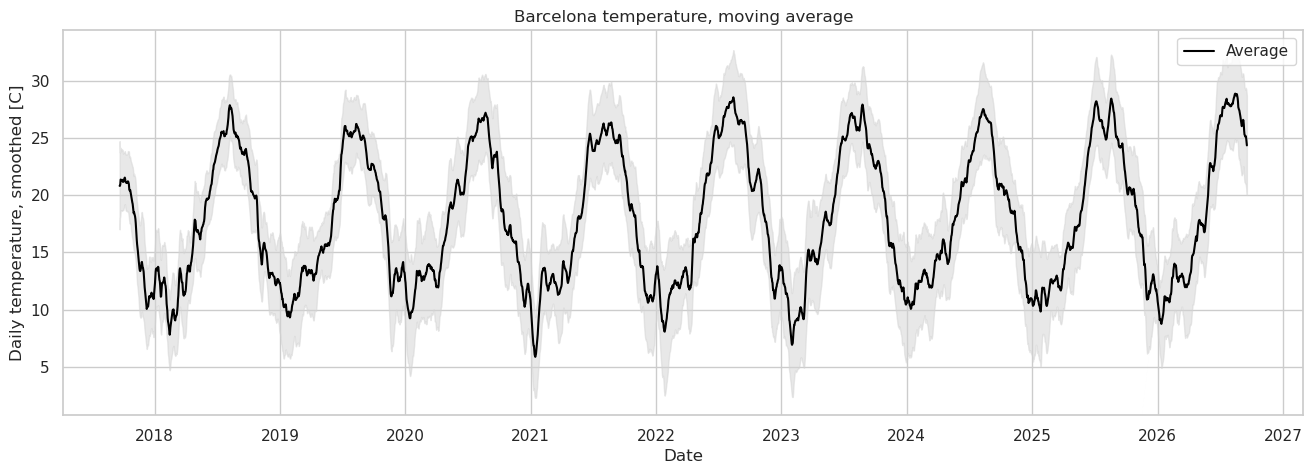

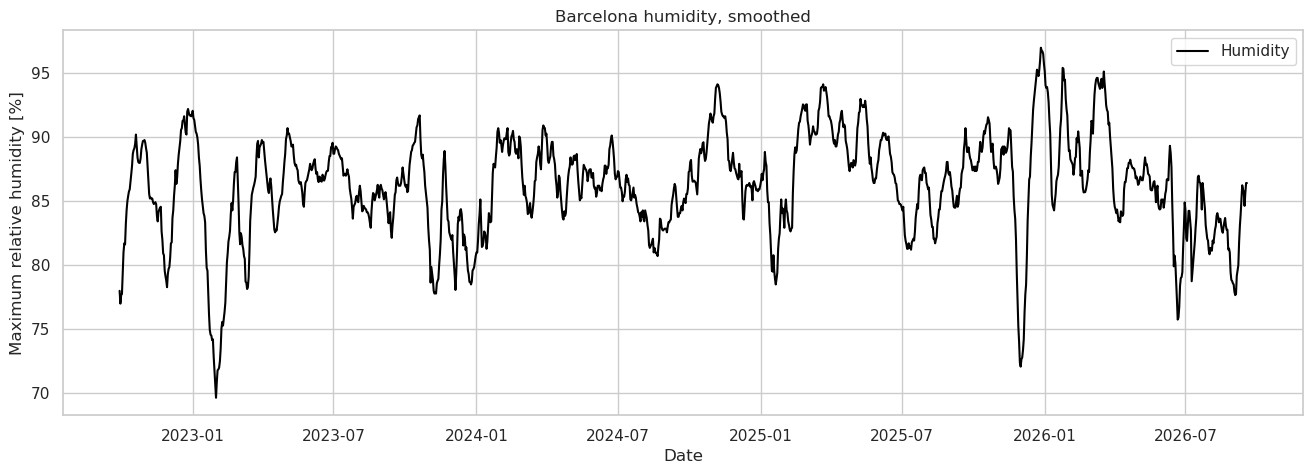

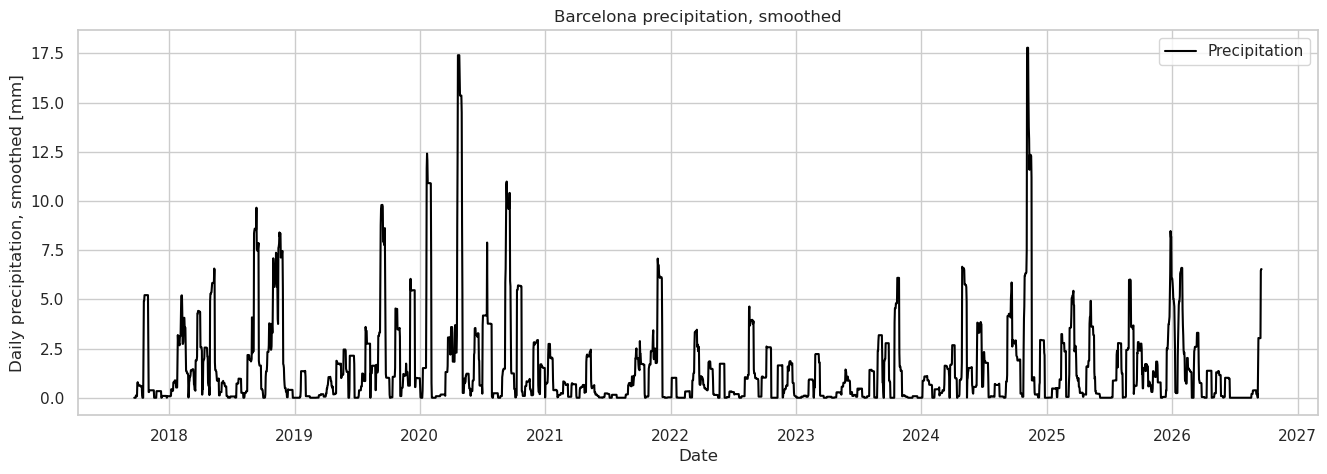

In [15]:
# LEAVE AS-IS

# Smooth over two weeks
weather_smoothed = moving_average(weather_sample, 14)

# Plot smoothed temperature
plot_min_max(weather_smoothed, ylabel='Daily temperature, smoothed [C]',
             title="Barcelona temperature, moving average", 
             min_col='temp_min', max_col='temp_max', avg_col='temp_avg')

# Plot smoothed humidity
plot_variable(weather_smoothed,
              title="Barcelona humidity, smoothed", 
                col="relhumidity_max", label="Humidity", ylabel="Maximum relative humidity [%]")

# Plot smoothed precipitation
plot_variable(weather_smoothed,
              title="Barcelona precipitation, smoothed", 
                col="rainfall", label="Precipitation", ylabel="Daily precipitation, smoothed [mm]")

<font size="+1" color="#2680EB">**Answer the following questions**</font>


**Answer:**

What is the main difficulty when implementing moving averages?

* YOUR ANSWER HERE

Do you have some new observation in the humidity series? Does it change your assessment regarding seasonality when you look at the smoothed series versus the original one.

* YOUR ANSWER HERE

# 2. Forecasting

We will next perform a simple auto-regressive forecasting.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

## 2.1. Create auto-correlation plots <font color="#2680EB">[10%]</font>

We will start by computing auto-correlation plots, which show to what extent a series is correlated with itself if we consider a certain `lag`, or time difference.

The function `lagged_series` returns the original series trimmed so it is the same length of the lagged series, and the lagged series computed by looking at *lag* periods in the past. 

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Implement the lagged_series computation**</font>

In [ ]:
def lagged_series(series, lag):
    original_trimmed = []
    lagged = []
    
    for i in range(len(series)):
        j = i - lag
        # YOUR ANSWER HERE
        
    return original_trimmed, lagged  

Test your function with the following code.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [17]:
# LEAVE AS-IS

assert ([44, 55, 66, 77, 88], [11, 22, 33, 44, 55]) == lagged_series(pd.Series([11,22,33,44,55,66,77,88]), 3)

assert ([33, 44, 55, 66, 77, 88], [11, 22, 33, 44, 55, 66]) == lagged_series(pd.Series([11,22,33,44,55,66,77,88]), 2)

assert ([22, 33, 44, 55, 66, 77, 88], [11, 22, 33, 44, 55, 66, 77]) == lagged_series(pd.Series([11,22,33,44,55,66,77,88]), 1)


The function `autocorrelation`, which you can leave as-is, simply computes Pearson's correlation between a series and the series lagged *lag* periods.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [18]:
# LEAVE AS-IS

# Computes the correlation between two vectors,
# but first removes positions in which any of the vectors is a NaN
def correlation_without_nan(x,y):
    positions_to_remove = ~np.logical_or(np.isnan(x), np.isnan(y))

    x_without_nan = np.compress(positions_to_remove, x)
    y_without_nan = np.compress(positions_to_remove, y)
    return stats.pearsonr(x_without_nan,y_without_nan)[0]  

# Compute autocorrelation
def autocorrelation(series, lag):
    x,y = lagged_series(series, lag)
            
    return correlation_without_nan(x,y)

Now we will create auto-correlation plots. Create a function `compute_autocorrelations(series, max_periods)` that returns all the auto-correlations of a series from period `0` to `max_periods-1`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Implement the compute_autocorrelations function.** This computes all auto-correlations of the series from period 0 to max_periods-1.</font>

In [ ]:
def compute_autocorrelations(series, max_periods):
    correlations = []

    # YOUR ANSWER HERE
    
    return correlations


We now use this function to create an array `auto_correlation_temp` containing the correlations of `weather['temp_avg']`, `auto_correlation_temp_max` containing the correlations of `weather['temp_max']`, and an array `auto_correlation_rainfall` containing the correlations of `weather['rainfall']`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [20]:
# LEAVE AS-IS

# Compute for up to 2 years
max_periods = 2*365

# Compute autocorrelations of max temperature, average temperature, relative humidity, and rainfall
print("Computing autocorrelations of the maximum temperature series")
auto_correlations_temp_max = compute_autocorrelations(weather_sample['temp_max'], max_periods)

print("Computing autocorrelations of the average temperature series")
auto_correlations_temp_avg = compute_autocorrelations(weather_sample['temp_avg'], max_periods)

print("Computing autocorrelations of the relative humidity series")
auto_correlations_relhumidity = compute_autocorrelations(weather_sample['relhumidity_max'], max_periods)

print("Computing autocorrelations of the rainfall series")
auto_correlations_rainfall = compute_autocorrelations(weather_sample['rainfall'], max_periods)

Computing autocorrelations of the maximum temperature series
Computing autocorrelations of the average temperature series
Computing autocorrelations of the relative humidity series
Computing autocorrelations of the rainfall series


Now we plot these.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [21]:
# LEAVE AS-IS

def plot_auto_correlations(correlations, xlabel="Lag (days)", ylabel="Autocorrelation"):

    # The instructor used Gemini to create this plot using seaborn

    # Apply Seaborn aesthetic theme
    sns.set_theme(style='whitegrid')

    # Figure
    plt.figure(figsize=(15, 4))

    # Plot correlation using Seaborn
    sns.lineplot(x=range(len(correlations)), y=correlations)

    # Add xticks every 10 periods
    plt.xticks(np.arange(0, len(correlations), 10), rotation=90)

    # Add a horizontal line at zero
    plt.axhline(0, color='black', linestyle='--', alpha=0.7)

    # Add labels
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    plt.show()

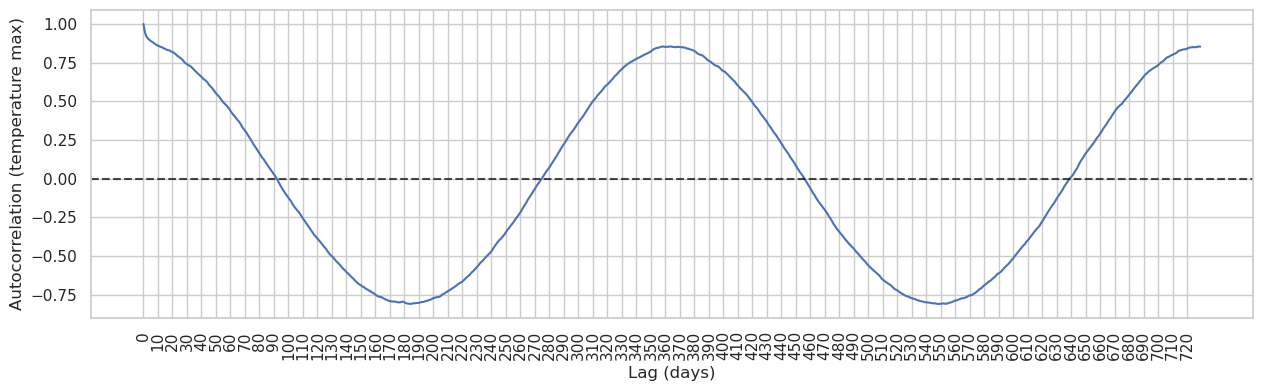

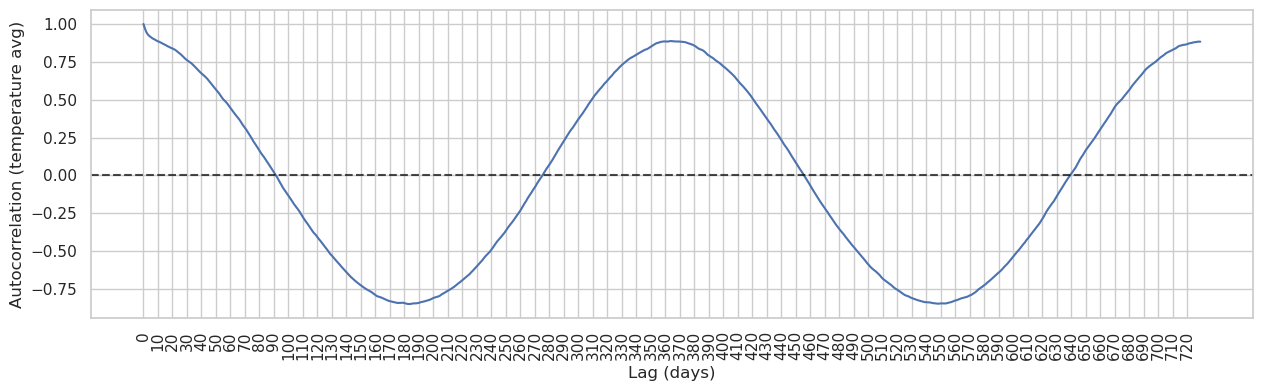

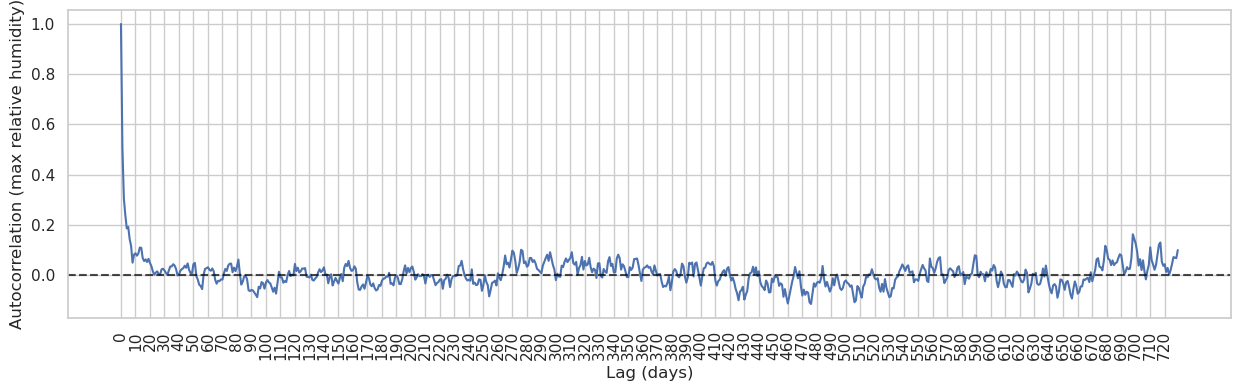

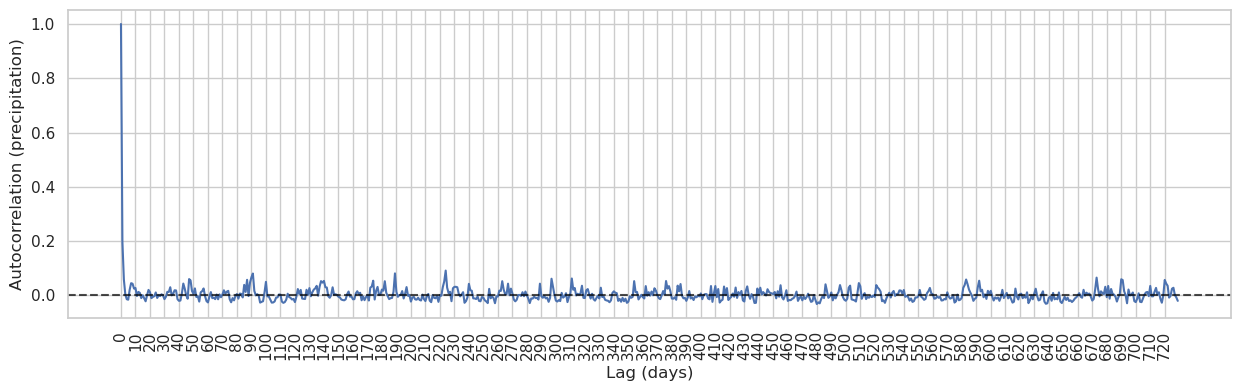

In [22]:
# LEAVE AS-IS

# Plot max temperature auto-correlation
plot_auto_correlations(auto_correlations_temp_max, ylabel="Autocorrelation (temperature max)")

# Plot avg temperature auto-correlation
plot_auto_correlations(auto_correlations_temp_avg, ylabel="Autocorrelation (temperature avg)")

# Plot max relative humidity auto-correlation
plot_auto_correlations(auto_correlations_relhumidity, ylabel="Autocorrelation (max relative humidity)")

# Plot precipitation auto-correlation
plot_auto_correlations(auto_correlations_rainfall, ylabel="Autocorrelation (precipitation)")

<font size="+1" color="#2680EB">**Answer the following questions.**</font>


**Answer:**

What do these autocorrelations indicate about the temperature data?

* YOUR ANSWER HERE

What do these autocorrelations indicate about the humidity data, when comparing them to the autocorrelations on the precipitation data?

* YOUR ANSWER HERE

Based on what you see in the autocorrelation plot, what is more unpredictable, humidity or precipitation?

* YOUR ANSWER HERE

## 2.2. Prepare for learning an auto-regressive model <font color="#2680EB">[20%]</font>

We will now learn an auto-regressive model, which computes the current value from a series of values in the past, at different *lags*.

**Example:** In the explanation we will assume there are two lags (2, 3) only. This means that the value will be predicted on the basis of the value observed 2 and 3 periods ago. The equation is then *y[i] = y[i-2] x alpha + y[i-3] x beta*, with *alpha* and *beta* being two unknown coefficients that we must determine. Suppose the series is: [11, 19, 32, 38, 51, 58, 68, 81]. From this series, we create the following system of equations.

* 19 x alpha + 11 x beta = 38
* 32 x alpha + 19 x beta = 51
* ...
* 58 x alpha + 51 x beta = 81

Unless the data is generated by a very specific process, we will seldom satisfy *exactly* this system of equations, but we can **approximately** satisfy it. We will use SciKit's [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) to obtain *alpha* and *beta*. To use this function, we need to prepare to matrices: *X*, which will contain the numbers in the left side of the equations, and *y* which will be a vector containing the numbers in the right side of the equations.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Implement the function prepare_matrices.** It should create a matrix with the coefficient of the system of equations that the forecasting model must solve.</font>

In [ ]:
def prepare_matrices(series, lags):
    y = []
    X = []
    series_values = np.asarray(series)
    
    for lag in lags:
        assert(lag > 0)
        assert(lag < len(series_values))
    
    for i in range(np.max(lags), len(series_values)):
        # YOUR ANSWER HERE
        
    return X, y

Test your code. Given the series *[11, 15, 32, 37, 52, 54, 70, 89]* and lags *[2, 3]*, you should obtain:

```python
X=[[15, 11], [32, 15], [37, 32], [52, 37], [54, 52]]
y=[37, 52, 54, 70, 89]
```

which means the system of equations:

```
15 x alpha + 11 x beta = 37
32 x alpha + 15 x beta = 52
...
52 x alpha + 52 x beta = 89
```

Where *alpha* is the coefficient of lag 2, and *beta* the cofficient of lag 3.

Notice that your code must handle well missing values. If any of the equations contains a NaN in the left or right side, you should discard it. In other words, *X* cannot contains vectors that have NaN values, and *y* cannot contain NaN values.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [24]:
# LEAVE AS-IS

X, y = prepare_matrices([11, 15, 32, 37, 52, 54, 70, 89], [2, 3])
assert X == [[15, 11], [32, 15], [37, 32], [52, 37], [54, 52]]
assert y == [37, 52, 54, 70, 89]

X, y = prepare_matrices([11, 15, np.nan, 37, 52, 54, 70, 89], [2, 3])
assert X == [[15, 11], [52, 37], [54, 52]]
assert y == [37, 70, 89]

## 2.3. Perform forecasts <font color="#2680EB">[20%]</font>

We first define a couple of functions to perform and plot the forecast, which you can leave as-is.

Function `perform_forecast` simply uses your `prepare_matrices` function to prepare a system of equations, and then calls [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) in SciKit-Learn to try to find a solution.

We measure the error as the RMSE (Root Mean Squared Error) divided by the difference between the maximum and minimum value we want to predict, i.e., the [NRMSD](https://en.wikipedia.org/wiki/Root-mean-square_deviation#Normalized_root-mean-square_deviation).

We also output the maximum absolute difference.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [25]:
# LEAVE AS-IS

def perform_forecast(series, lags):

    # Prepare matrices for linear regression
    X, y = prepare_matrices(series, lags)

    # Perform forecast
    linear_regressor = LinearRegression()
    linear_regressor.fit(X,y)
    y_pred = linear_regressor.predict(X)

    # Compute forecasting error

    # Normalized root mean square deviation (NRMSD)
    rmse = math.sqrt(mean_squared_error(y, y_pred))/(np.max(y)-np.min(y))

    # Maximum absolute difference
    max_absolute_diff = np.max(np.abs(y - y_pred))
    
    # Return: observed, predicted, error
    return (y, y_pred, rmse, max_absolute_diff)

We plot the forecast using the next function.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [26]:
# LEAVE AS-IS

def plot_forecast(y, y_pred, xlabel="Period", ylabel="", nrmsd=np.nan):

    plt.figure(figsize=(15, 4))
    periods = range(len(y))

    # The instructor used Gemini to create this plot using seaborn
    sns.lineplot(x=periods, y=y, color='gray', marker='.', linewidth=4,
                 label='Observed')
    sns.lineplot(x=periods, y=y_pred, color='green', linestyle='--',
                 linewidth=2,
                 label=('Model (NRMSD=%.2f)' % nrmsd if not np.isnan(nrmsd) else 'Model'))

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend()
    plt.show()

First, predict the daily temperature. Set `lags_daily_temperature = [...]` to be an array of up to 4 lags. Use the auto-correlation plots you draw before as a guideline.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Indicate your choice of lags in the next cell,** as array lags_daily_temperature</font>

In [ ]:
lags_daily_temperature = # YOUR ANSWER HERE


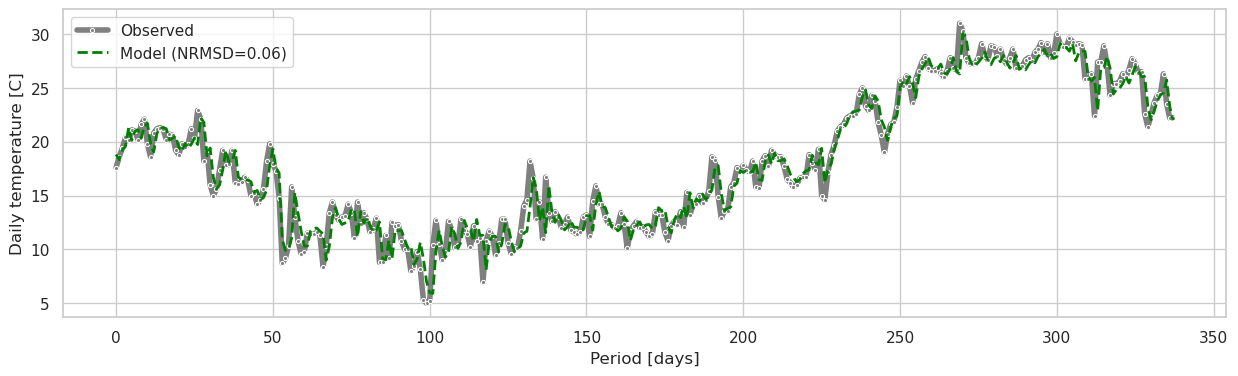

In [28]:
# LEAVE AS-IS
# Plot predicted and actual temperature in the last 720 days of the sample

(y, y_pred, nrmsd, maxdiff) = perform_forecast(weather_sample['temp_avg'][-720:],
                                      lags_daily_temperature)

plot_forecast(y, y_pred,
              xlabel="Period [days]",
              ylabel="Daily temperature [C]",
              nrmsd=nrmsd)

<font size="+1" color="#2680EB">**Answer the following questions.**</font>


**Answer:**

How accurate are your predictions? What is the maximum difference between the temperature you predict and the one that you observe? 

* YOUR ANSWER HERE

Next, we predict the daily maximum of relative humidity; set `lags_relhumidity_max = [...]` to be an array of up to 4 lags. Use the auto-correlation plots you draw before as a guideline.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

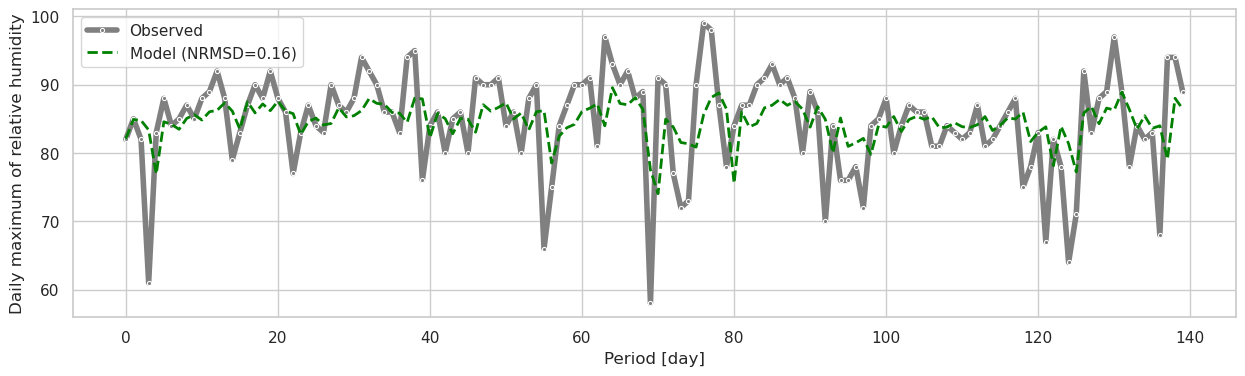

In [ ]:
lags_relhumidity_max = # YOUR ANSWER HERE

# LEAVE AS-IS
(y, y_pred, nrmsd, maxdiff) = perform_forecast(weather_sample['relhumidity_max'][-180:],
                                      lags_relhumidity_max)

plot_forecast(y, y_pred,
              xlabel="Period [day]",
              ylabel="Daily maximum of relative humidity",
              nrmsd=nrmsd)

<font size="+1" color="#2680EB">**Answer the following questions.**</font>


**Answer:**

How accurate is your prediction of relative humidity? How is this in comparison to your prediction of daily temperature?

* YOUR ANSWER HERE

# DELIVER (individually)

Remember to read the section on "delivering your code" in the [course evaluation guidelines](https://github.com/chatox/data-mining-course/blob/master/upf/upf-evaluation.md).

Deliver this notebook, renamed as `PSxx_Unnnnnn_YourName.ipynb` where:
* *PSxx* is the practice number.
* *Unnnnnn* is your UPF id number.
* *YourName* is your name.

## Extra points available

For more learning and extra points, create a model for temperature that uses cross-correlations. This means, you can use the variables *temp_min*, *temp_avg*, *temp_max*, *rainfall*, *relhumidity_min*, *relhumidity_max*, *windspeed_avg*, and *windspeed_gusts* up to the previous day to predict *temp_avg* on the current day. You only need to be careful not to include any `lag=0` measure, otherwise you would not be predicting the future. Include plots and a brief commentary indicating whether you obtained any improvements.

**Note:** if you go for the extra points, add ``<font size="+2" color="#2680EB">Additional results: cross correlations</font>`` at the top of your notebook. 

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that my answers were not written by an AI-enabled code assistant, and that except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>